# Zak-OTFS (OTFS 2.0): решётка Зака и предсказуемый канал

В `otfs_sim` OTFS собиралась как прекодер поверх OFDM: ISFFT → OFDM-модулятор. Это «OTFS 1.0». Её слабое место видно в разделе 5 того ноутбука: при **дробном** доплере отклик на пилот размазан ядром Дирихле, модель «целых лучей» неверна, и BER упирается в пол.

**Zak-OTFS** (Mohammed, Hadani, Chockalingam, Calderbank, 2022–2024) строит ту же идею из первых принципов, через **преобразование Зака**:
$$Z_x(\tau,\nu)=\sqrt{\tau_p}\sum_{k\in\mathbb Z}x(\tau+k\tau_p)\,e^{-j2\pi\nu k\tau_p},\qquad \tau_p\nu_p=1 .$$
Это промежуточное представление между временем и частотой: функция на плоскости задержка–доплер, **квазипериодическая** с периодами $\tau_p$ по задержке и $\nu_p$ по доплеру:
$$Z(\tau+n\tau_p,\nu+m\nu_p)=e^{j2\pi n\nu\tau_p}\,Z(\tau,\nu).$$
Канал $r(t)=\sum_ih_ie^{j2\pi\nu_it}s(t-\tau_i)$ действует на неё **скрученной свёрткой**
$$Y(\tau,\nu)=\iint h(\tau',\nu')\,e^{j2\pi\nu'(\tau-\tau')}\,X(\tau-\tau',\nu-\nu')\,d\tau'd\nu' .$$
Фаза-«скрутка» появляется потому, что задержка и доплер не коммутируют: $T_\tau D_\nu=e^{-j2\pi\nu\tau}D_\nu T_\tau$.

Главное свойство — **предсказуемость**. Если канал «кристаллизуется», то есть его разброс меньше периодов ($\tau_{\max}<\tau_p$, $2\nu_{\max}<\nu_p$), а импульс модуляции хорошо локализован в DD, то отклик на **один** пилот определяет отклик на **любой** символ, без всякой модели лучей. Это и чинит дробный доплер. Импульс здесь важен: прямоугольное окно во времени (как в OTFS 1.0) даёт хвосты Дирихле $\propto1/\Delta\nu$, гауссово — хвосты $e^{-\Delta\nu^2}$.

Модель в этом ноутбуке упрощена: целые задержки, дробный доплер, фильтр только по оси доплера (окно во времени). Цифры кадра те же, что в `otfs_sim` (64×16, $\nu_p=15$ кГц, 500 км/ч), так что результаты сравнимы напрямую.

1. Квазипериодичность и пульсон · 
2. Некоммутативность и скрученная свёртка ·
3. Окно = фильтр в DD: Дирихле против Гаусса · 
4. Предсказуемость и кристаллизация ·
5. Оценка канала без модели: BER · 
6. Сенсинг: доплер цели по одному пилоту

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import erfc

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
M, N = 64, 16          # бинов задержки на периоде τp × бинов доплера на периоде νp
DF = 15e3              # νp = Δf, τp = 1/Δf: тот же кадр, что в otfs_sim
FC_GHZ = 4.0
SPEED_KMH = 500
P_PATHS = 5            # задержки 0…P−1 отсчётов (целые), доплер дробный
SIGMA = 0.25           # ширина гауссова окна по времени, доля кадра MN (фильтр по оси доплера)
L_CP = 8               # CP для прямоугольного окна (классическая OTFS)
FRAMES = 20

rng = np.random.default_rng(SEED)

## Примитивы: дискретное преобразование Зака, окна, канал, скрученная свёртка, предсказание H по пилоту

In [2]:
MN = M * N
FS = M * DF; T = N / DF                       # отсчёт 1/B, кадр T = N·τp
TAU_P, NU_P = 1 / DF, DF
NU_MAX = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
K_MAX = NU_MAX * T                            # доплер в бинах 1/T
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)
SPAN = (-MN // 2, 3 * MN // 2)                # абсолютные отсчёты, которые моделируем (кадр — [0, MN))
NABS = np.arange(*SPAN)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qpsk_bits(B, n, rng):
    b = rng.integers(0, 2, (B, n, 2))
    return b, QPSK[b[..., 0] + 2 * b[..., 1]]

def hard_bits(z):
    return np.stack([z.real < 0, z.imag < 0], -1).astype(int)

# ---------- дискретное преобразование Зака ----------
def idzt(X):
    """DD (…, M, N) → один период x[k + nM] = (1/√N) Σ_l X[k,l]·e^{j2πnl/N}, n = 0…N−1"""
    return (np.fft.ifft(X, axis=-1) * np.sqrt(N)).swapaxes(-1, -2).reshape(X.shape[:-2] + (MN,))

def dzt(y, n_abs=NABS):
    """Z[k,l] = (1/√N) Σ_{n ∈ ℤ} y[k + nM]·e^{−j2πnl/N} по всем блокам сигнала (бесконечная сумма = свёртка блоков по модулю N)."""
    blocks = y.reshape(y.shape[:-1] + (-1, M))                       # блок b начинается в n_abs[0] + bM
    b0 = n_abs[0] // M
    fold = np.zeros(y.shape[:-1] + (N, M), complex)
    for b in range(blocks.shape[-2]):
        fold[..., (b0 + b) % N, :] += blocks[..., b, :]
    return (np.fft.fft(fold, axis=-2) / np.sqrt(N)).swapaxes(-1, -2)

def qp(Y, k, l):
    """значение квазипериодической функции в любой точке (k, l): Y[k + nM, l] = e^{j2πnl/N}·Y[k, l], Y[k, l + N] = Y[k, l]"""
    n = np.floor_divide(k, M)
    return Y[..., k % M, l % N] * np.exp(2j * np.pi * n * l / N)

# ---------- окна: фильтр по оси доплера = окно во времени ----------
def windows(kind, sigma=SIGMA):
    """'rect' — классическая OTFS: передача на [−CP, MN), приём на [0, MN). 'gauss' — гауссовы окна TX и RX с СКО σ·MN."""
    if kind == "rect":
        gt = ((NABS >= -L_CP) & (NABS < MN)).astype(float); gr = ((NABS >= 0) & (NABS < MN)).astype(float)
    else:
        gt = gr = np.exp(-(NABS - MN / 2)**2 / (2 * (sigma * MN)**2))
    return gt * np.sqrt(MN / np.sum(gt**2)), gr * np.sqrt(MN / np.sum(gr**2))

def tx(X, gt):
    """DD → периодический сигнал на всём SPAN × окно TX. Энергия кадра = MN·Es."""
    return idzt(X)[..., NABS % MN] * gt

def rx(r, gr):
    return dzt(r * gr)

def channel(s, paths):
    """r[n] = Σ h_i·e^{j2πν_i n/f_s}·s[n − l_i], n — абсолютное время (целые задержки, любой доплер)"""
    r = np.zeros(s.shape, complex)
    for h, l, nu in paths:
        r[..., l:] += h * np.exp(2j * np.pi * nu * NABS[l:] / FS) * s[..., :s.shape[-1] - l]
    return r

def draw_paths(rng, integer=False, nu_max=None):
    nu_max = NU_MAX if nu_max is None else nu_max
    p = np.exp(-np.arange(P_PATHS) / 1.5); p /= p.sum()
    nu = nu_max * np.cos(rng.uniform(0, 2 * np.pi, P_PATHS))
    if integer:
        nu = np.round(nu * T) / T
    return [(np.sqrt(pi) * crandn((), rng), l, v) for l, (pi, v) in enumerate(zip(p, nu))]

EYE = np.eye(MN, dtype=complex).reshape(MN, M, N)

def eff_matrix(paths, kind, sigma=None):
    gt, gr = windows(kind, SIGMA if sigma is None else sigma)
    return rx(channel(tx(EYE, gt), paths), gr).reshape(MN, MN).T

def noise_whitener(kind):
    """шум после окна RX и DZT коррелирован: C = R·Rᴴ; возвращаем L⁻¹ (C = L·Lᴴ)"""
    _, gr = windows(kind)
    R = dzt(np.eye(len(NABS), dtype=complex) * gr).reshape(len(NABS), MN).T
    return np.linalg.inv(np.linalg.cholesky(R @ R.conj().T + 1e-9 * np.eye(MN)))

def lmmse(H, y, n0):
    return np.linalg.solve(H.conj().T @ H + n0 * np.eye(H.shape[1]), H.conj().T @ y.T).T

# ---------- скрученная свёртка и предсказание канала по пилоту ----------
def read_h(Yp, kp, lp, D, Q):
    """h[d, q] = Y_p[k_p + d, l_p + q]·e^{−j2πq(k_p + d)/MN} на окне d ∈ [D0, D1], q ∈ [−Q, Q]"""
    d = np.arange(D[0], D[1] + 1)[:, None]; q = np.arange(-Q, Q + 1)[None, :]
    return d, q, qp(Yp, kp + d, lp + q) * np.exp(-2j * np.pi * q * (kp + d) / MN)

def predict_H(d, q, h):
    """H[:, (k0,l0)]: y[k0+d, l0+q] = h[d,q]·e^{j2πq(k0+d)/MN}, затем приведение к основной области по квазипериодичности"""
    H = np.zeros((MN, MN), complex)
    k0, l0 = np.divmod(np.arange(MN), N)
    for (dd, qq), hv in np.ndenumerate(h):
        k = k0 + d[dd, 0]; l = l0 + q[0, qq]
        val = hv * np.exp(2j * np.pi * q[0, qq] * k / MN) * np.exp(-2j * np.pi * np.floor_divide(k, M) * l / N)
        np.add.at(H, ((k % M) * N + l % N, np.arange(MN)), val)
    return H

# самопроверки
_, _x = qpsk_bits(2, MN, rng); _X = _x.reshape(2, M, N)
_y = dzt(idzt(_X)[..., NABS % MN] * ((NABS >= 0) & (NABS < MN)))
assert np.allclose(_y, _X), "DZT ∘ IDZT"
print(f"τp = {TAU_P*1e6:.1f} мкс, νp = {NU_P/1e3:.0f} кГц, τp·νp = {TAU_P*NU_P:.0f}; сетка {M}×{N}: Δτ = τp/M = {TAU_P/M*1e6:.2f} мкс, Δν = νp/N = {NU_P/N:.1f} Гц")
print(f"{SPEED_KMH} км/ч на {FC_GHZ} ГГц: ν_max = {NU_MAX:.0f} Гц = {K_MAX:.2f} бина; кристаллизация: τ_max = {P_PATHS-1} ≪ M = {M}, 2ν_max = {2*K_MAX:.1f} < N = {N} бинов")

τp = 66.7 мкс, νp = 15 кГц, τp·νp = 1; сетка 64×16: Δτ = τp/M = 1.04 мкс, Δν = νp/N = 937.5 Гц
500 км/ч на 4.0 ГГц: ν_max = 1852 Гц = 1.98 бина; кристаллизация: τ_max = 4 ≪ M = 64, 2ν_max = 4.0 < N = 16 бинов


## 1. Квазипериодичность и пульсон
Дискретный вариант: $Z[k,l]=\frac1{\sqrt N}\sum_{n\in\mathbb Z}y[k+nM]\,e^{-j2\pi nl/N}$, $k$ — задержка в отсчётах $1/B$, $l$ — доплер в бинах $1/T$. Сумма по **всем** блокам сигнала, а не по одному кадру. Квазипериодичность $Z[k+M,l]=e^{j2\pi l/N}Z[k,l]$ проверяется до машинной точности.

Символ в точке $(k_0,l_0)$ — **пульсон**: во времени это импульсы через $\tau_p$, фаза которых вращается с частотой $l_0\nu_p/N$, а в частоте — гребёнка через $\nu_p$, сдвинутая на $l_0\nu_p/N$. Ни во времени, ни в частоте он не локализован, но локализован на решётке DD. Окно во времени — это фильтр по оси доплера:
- **прямоугольное** (OTFS 1.0): ровно $N$ импульсов, без канала символы ортогональны;
- **гауссово**: огибающая импульсов колокол. Без канала оно уже связывает соседние бины доплера (справа: 0.54 на ±1), то есть символы не ортогональны. За локализацию платим неортогональностью, это ещё скажется в разделе 5.

Квазипериодичность: max|Z[k+M,l] − e^(j2πl/N)·Z[k,l]| = 3.4e-16, max|Z[k,l+N] − Z[k,l]| = 2.0e-15


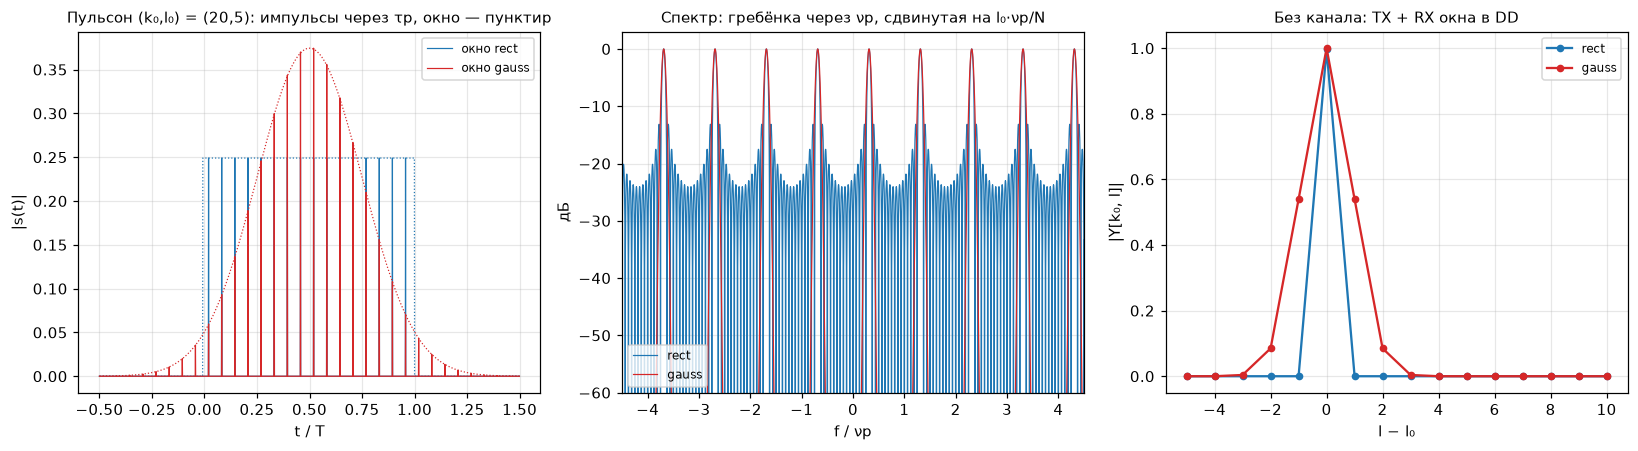

Гауссово окно σ = 0.25·T: 99 % энергии на 0.91·T — не длиннее кадра, но края кадра почти пусты, а середина нагружена сильнее
Без канала гауссовы окна сами дают межсимвольную связь по доплеру: |Y[k₀, l₀±1]| = 0.540, |Y[k₀, l₀±2]| = 0.085


In [3]:
# (а) квазипериодичность
x = idzt(_X[0])
Xbig = dzt(x[NABS % MN] * ((NABS >= 0) & (NABS < MN)))
k, l = np.meshgrid(np.arange(-M, 2 * M), np.arange(-N, 2 * N), indexing="ij")
print(f"Квазипериодичность: max|Z[k+M,l] − e^(j2πl/N)·Z[k,l]| = {np.max(np.abs(qp(Xbig, k + M, l) - np.exp(2j*np.pi*l/N) * qp(Xbig, k, l))):.1e}, "
      f"max|Z[k,l+N] − Z[k,l]| = {np.max(np.abs(qp(Xbig, k, l + N) - qp(Xbig, k, l))):.1e}")

# (б) пульсон: один DD-символ во времени и по частоте
k0, l0 = 20, 5
P = np.zeros((M, N), complex); P[k0, l0] = 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, kind, c in ((ax[0], "rect", "C0"), (ax[0], "gauss", "C3")):
    gt, _ = windows(kind)
    s = tx(P, gt)
    a.plot(NABS / MN, np.abs(s), c, lw=0.8, label=f"окно {kind}")
    a.plot(NABS / MN, gt / gt.max() * np.abs(s).max(), c + ":", lw=0.8)
ax[0].set_xlabel("t / T"); ax[0].set_ylabel("|s(t)|"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Пульсон (k₀,l₀) = ({k0},{l0}): импульсы через τp, окно — пунктир", fontsize=10)
for kind, c in (("rect", "C0"), ("gauss", "C3")):
    gt, _ = windows(kind)
    S = np.fft.fftshift(np.fft.fft(tx(P, gt), 8 * len(NABS))); f = np.fft.fftshift(np.fft.fftfreq(8 * len(NABS), 1 / FS))
    ax[1].plot(f / DF, 20 * np.log10(np.abs(S) / np.abs(S).max() + 1e-9), c, lw=0.8, label=kind)
ax[1].set_xlim(-4.5, 4.5); ax[1].set_ylim(-60, 3); ax[1].set_xlabel("f / νp"); ax[1].set_ylabel("дБ"); ax[1].legend(fontsize=8)
ax[1].set_title("Спектр: гребёнка через νp, сдвинутая на l₀·νp/N", fontsize=10)
for kind, c in (("rect", "C0"), ("gauss", "C3")):
    gt, gr = windows(kind)
    Y = rx(tx(P, gt), gr)
    ax[2].plot(np.arange(N) - l0, np.abs(Y[k0]), c + "o-", ms=4, label=kind)
ax[2].set_xlabel("l − l₀"); ax[2].set_ylabel("|Y[k₀, l]|"); ax[2].legend(fontsize=8)
ax[2].set_title("Без канала: TX + RX окна в DD", fontsize=10)
plt.tight_layout(); plt.show()
gt, gr = windows("gauss")
e = np.cumsum(np.sort(gt**2)[::-1]) / np.sum(gt**2)
print(f"Гауссово окно σ = {SIGMA}·T: 99 % энергии на {np.argmax(e > 0.99)/MN:.2f}·T — не длиннее кадра, но края кадра почти пусты, а середина нагружена сильнее")
Y = rx(tx(P, gt), gr)
print(f"Без канала гауссовы окна сами дают межсимвольную связь по доплеру: |Y[k₀, l₀±1]| = {abs(Y[k0, l0+1]):.3f}, |Y[k₀, l₀±2]| = {abs(Y[k0, l0+2]):.3f}")

## 2. Некоммутативность и скрученная свёртка
Сдвиг на $d$ отсчётов и доплер на $q$ бинов в разном порядке дают сигналы, отличающиеся множителем $e^{-j2\pi qd/MN}$: это проверка первой строкой вывода. Отсюда дискретный вход–выход для луча $(h,d,q)$ с целыми $d,q$:
$$y[k,l]=h\,e^{\,j2\pi qk/MN}\,x[k-d,\,l-q],$$
где $x$ продолжено квазипериодически. Это **точно** совпадает с моделированием во времени. Обычная 2D-свёртка без фазы ошибается на 36 %.

На рисунке — отклики на пилоты в двух местах кадра. Модули одинаковые, а фазы — разные, и их предсказывает скрутка. В OTFS 1.0 эти фазы $\phi_i(l,k)$ приходилось выводить для конкретного модема. Здесь они — свойство плоскости DD.

T_τ D_ν = e^(−j2πντ)·D_ν T_τ: отношение = (0.9993-0.0368j), теория e^(−j2π q d/MN) = (0.9993-0.0368j) (одинаково для всех n: разброс 3.7e-15)


Скрученная свёртка y[k,l] = Σ h_i·e^(j2π q_i k/MN)·x[k − d_i, l − q_i] против моделирования во времени: max|Δ| = 2.4e-15
Без «скрутки» (обычная 2D-свёртка): относительная ошибка 0.36 — фаза e^(j2πqk/MN) не мелочь


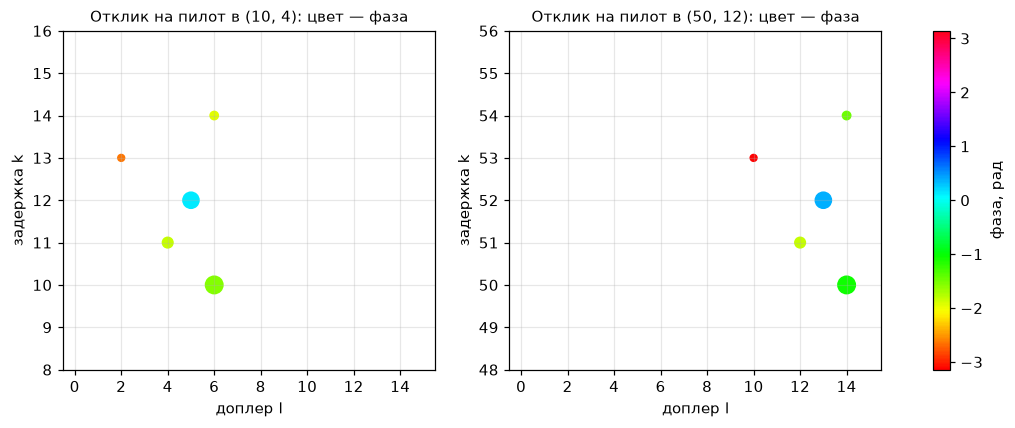

In [4]:
# сдвиги по задержке и доплеру не коммутируют
s = crandn(len(NABS), rng); d, q = 3, 2.0
Tz = lambda v: np.r_[np.zeros(d), v[:-d]]
Dz = lambda v: v * np.exp(2j * np.pi * q * NABS / MN)
ratio = Tz(Dz(s))[d:] / Dz(Tz(s))[d:]
print(f"T_τ D_ν = e^(−j2πντ)·D_ν T_τ: отношение = {np.round(ratio[0], 4)}, теория e^(−j2π q d/MN) = {np.round(np.exp(-2j*np.pi*q*d/MN), 4)} (одинаково для всех n: разброс {np.ptp(np.abs(ratio - ratio[0])):.1e})")

# вход–выход: скрученная свёртка против моделирования во времени
pth = draw_paths(np.random.default_rng(3), integer=True)
H = eff_matrix(pth, "rect")
_, xd = qpsk_bits(1, MN, rng); X = xd[0].reshape(M, N)
y_time = (H @ xd[0]).reshape(M, N) / (windows("rect")[0].max() * windows("rect")[1].max())   # без нормировки окон по энергии
kk, ll = np.meshgrid(np.arange(M), np.arange(N), indexing="ij")
y_tw = sum(h * np.exp(2j * np.pi * (nu * T) * kk / MN) * qp(X, kk - l, ll - int(round(nu * T))) for h, l, nu in pth)
print(f"Скрученная свёртка y[k,l] = Σ h_i·e^(j2π q_i k/MN)·x[k − d_i, l − q_i] против моделирования во времени: max|Δ| = {np.max(np.abs(y_tw - y_time)):.1e}")
y_naive = sum(h * qp(X, kk - l, ll - int(round(nu * T))) for h, l, nu in pth)
print(f"Без «скрутки» (обычная 2D-свёртка): относительная ошибка {np.linalg.norm(y_naive - y_time)/np.linalg.norm(y_time):.2f} — фаза e^(j2πqk/MN) не мелочь")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (kp, lp) in zip(ax, ((10, 4), (50, 12))):
    Pp = np.zeros((M, N), complex); Pp[kp, lp] = 1
    Yp = (H @ Pp.ravel()).reshape(M, N)
    m = np.abs(Yp) > 1e-6
    ki, li = np.nonzero(m)
    sc = a.scatter(li, ki, c=np.angle(Yp[m]), s=120 * np.abs(Yp[m]) / np.abs(Yp).max() + 10, cmap="hsv", vmin=-np.pi, vmax=np.pi)
    a.set_xlim(-0.5, N - 0.5); a.set_ylim(kp - 2, kp + P_PATHS + 1)
    a.set_xlabel("доплер l"); a.set_ylabel("задержка k"); a.set_title(f"Отклик на пилот в ({kp}, {lp}): цвет — фаза", fontsize=10)
plt.colorbar(sc, ax=ax, label="фаза, рад"); plt.show()

## 3. Окно = фильтр в DD: Дирихле против Гаусса
Один луч с доплером ровно посередине между бинами (3.5 бина). Отклик в DD — это спектр произведения окон TX·RX, сдвинутый на $\nu$:
- **прямоугольник** длины $T$ → $\big|\frac{\sin\pi\Delta\nu T}{N\sin(\pi\Delta\nu T/N)}\big|$: хвосты падают как $1/\Delta\nu$, вне 4 ближайших бинов остаётся 9 % энергии;
- **гаусс** с СКО $\sigma$ (у произведения $\sigma/\sqrt2$) → $\exp\!\big(-2\pi^2(\sigma/\sqrt2)^2\Delta\nu^2\big)$: вне 4 бинов 0.06 %.

Точки симуляции ложатся на обе формулы.

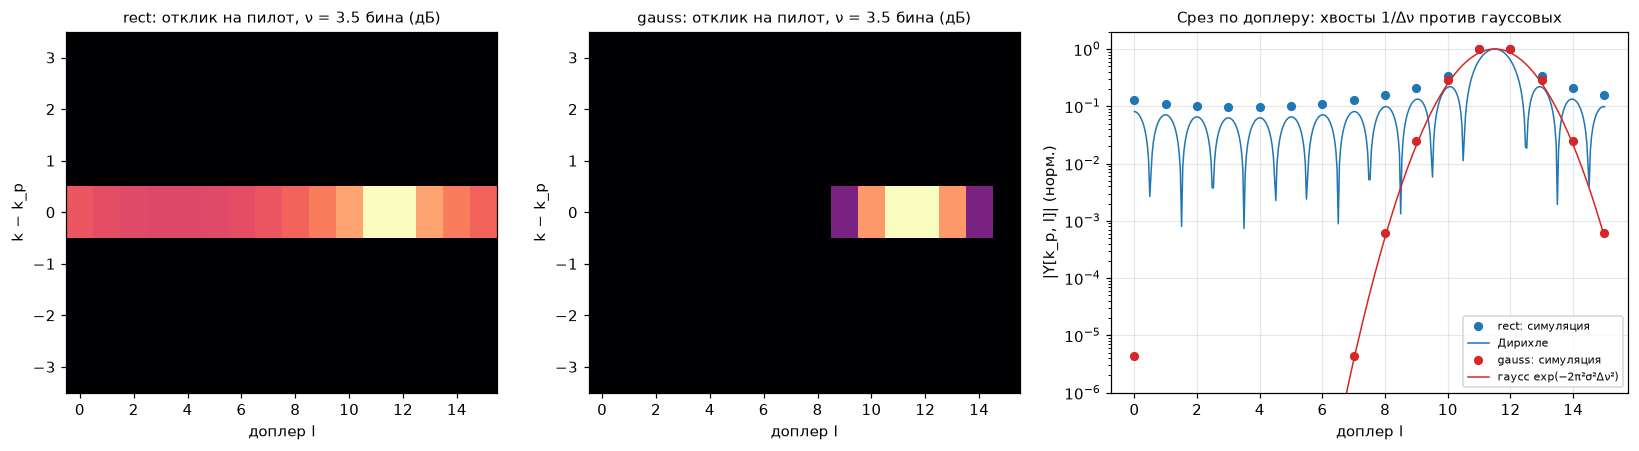

rect : энергия вне 2 / 4 ближайших бинов 18.7% / 9.41%
gauss: энергия вне 2 / 4 ближайших бинов 7.9% / 0.06%


In [5]:
from scipy.special import erf
def dirichlet(x):
    with np.errstate(invalid="ignore", divide="ignore"):
        v = np.abs(np.sin(np.pi * x) / (N * np.sin(np.pi * x / N)))
    return np.where(np.abs(np.sin(np.pi * x / N)) < 1e-12, 1.0, v)

one = [(1.0, 0, 3.5 / T)]                                     # один луч, доплер ровно посередине между бинами
kp, lp = M // 2, N // 2
Pp = np.zeros((M, N), complex); Pp[kp, lp] = 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.2]})
cuts = {}
for a, kind in zip(ax[:2], ("rect", "gauss")):
    gt, gr = windows(kind)
    Y = rx(channel(tx(Pp, gt), one), gr)
    cuts[kind] = np.abs(Y[kp]) / np.abs(Y).max()
    a.imshow(20 * np.log10(np.abs(Y[kp - 3:kp + 4]) / np.abs(Y).max() + 1e-9), origin="lower", aspect="auto", cmap="magma",
             vmin=-50, vmax=0, extent=[-0.5, N - 0.5, -3.5, 3.5])
    a.set_xlabel("доплер l"); a.set_ylabel("k − k_p"); a.grid(False)
    a.set_title(f"{kind}: отклик на пилот, ν = {3.5} бина (дБ)", fontsize=10)
lg = np.linspace(0, N - 1, 400)
ax[2].semilogy(np.arange(N), cuts["rect"], "C0o", ms=5, label="rect: симуляция")
ax[2].semilogy(lg, dirichlet(lg - lp - 3.5), "C0-", lw=1, label="Дирихле")
sg = SIGMA * MN / np.sqrt(2)                                   # СКО произведения окон TX·RX
theory = np.exp(-2 * (np.pi * sg * (lg - lp - 3.5) / MN)**2)
ax[2].semilogy(np.arange(N), cuts["gauss"], "C3o", ms=5, label="gauss: симуляция")
ax[2].semilogy(lg, theory, "C3-", lw=1, label="гаусс exp(−2π²σ²Δν²)")
ax[2].set_ylim(1e-6, 2); ax[2].set_xlabel("доплер l"); ax[2].set_ylabel("|Y[k_p, l]| (норм.)"); ax[2].legend(fontsize=7)
ax[2].set_title("Срез по доплеру: хвосты 1/Δν против гауссовых", fontsize=10)
plt.tight_layout(); plt.show()
for kind in cuts:
    c2 = cuts[kind]**2 / np.sum(cuts[kind]**2); near = np.sort(c2)[::-1]
    print(f"{kind:5}: энергия вне 2 / 4 ближайших бинов {1 - near[:2].sum():.1%} / {1 - near[:4].sum():.2%}")

## 4. Предсказуемость и кристаллизация
Эксперимент без шума. Берём отклик на один пилот, читаем из него $h[d,q]$ на окне вокруг пилота (по всей оси доплера), строим по скрученной свёртке **всю** матрицу $H_\text{eff}$ ($MN\times MN$) и сравниваем с настоящей:
$$h[d,q]=Y_p[k_p+d,\,l_p+q]\,e^{-j2\pi q(k_p+d)/MN},\qquad \hat y_{k_0,l_0}[k_0+d,l_0+q]=h[d,q]\,e^{j2\pi q(k_0+d)/MN}.$$
- **Прямоугольное окно, целый доплер** — точно, до машинной точности.
- **Прямоугольное окно, дробный доплер** — NMSE ≈ −20 дБ. Отклик на символ у края кадра обрезан окном иначе, чем отклик на пилот. Это тот самый пол из `otfs_sim`.
- **Гауссово окно** — до −150 дБ: сигнал сам затухает к краям, обрезать нечего, и система становится инвариантной к скрученным сдвигам. Слишком узкое окно ($\sigma=0.12T$) расплывается по доплеру шире периода $\nu_p$ (наложение), слишком широкое ($0.5T$) обрезается границами моделирования. Есть оптимум.

Справа — **кристаллизация**: при $\nu_{\max}\to\nu_p/2$ отклик по доплеру начинает заворачиваться через период, и предсказание ломается для любого окна. Условие $2\nu_{\max}+\text{ширина фильтра}<\nu_p$ задаёт выбор $\nu_p$ (то есть $\Delta f$) под сценарий.

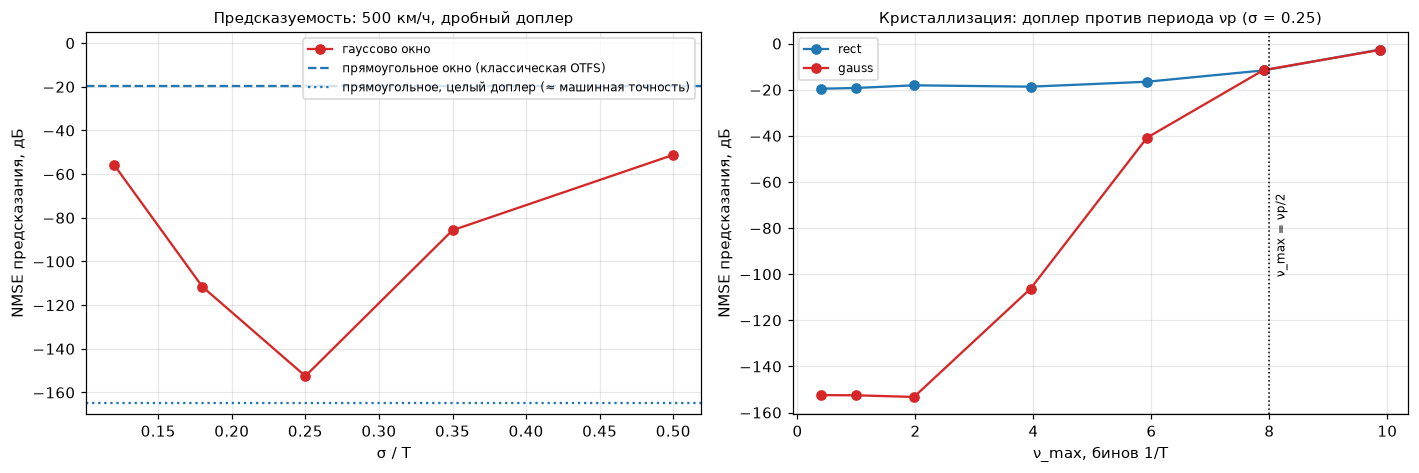

NMSE предсказания: rect, целый доплер -299 дБ; rect, дробный -19.6 дБ; гаусс σ = 0.25: -152.5 дБ


In [6]:
def predict_nmse(kind, pth, Q, sigma=None):
    """NMSE предсказания H_eff по отклику на один пилот (без шума)"""
    H = eff_matrix(pth, kind, sigma)
    Yp = (H[:, kp * N + lp]).reshape(M, N)
    d, q, h = read_h(Yp, kp, lp, (-3, P_PATHS + 2), Q)
    Hp = predict_H(d, q, h)
    return np.sum(np.abs(Hp - H)**2) / np.sum(np.abs(H)**2)

sigmas = [0.12, 0.18, 0.25, 0.35, 0.5]
res = {"rect": [], "gauss": []}; res_i = []
for f in range(6):
    r = np.random.default_rng(200 + f)
    pf = draw_paths(r)
    res["rect"].append(predict_nmse("rect", pf, N // 2 - 1))
    res["gauss"].append([predict_nmse("gauss", pf, N // 2 - 1, sgm) for sgm in sigmas])
    res_i.append(predict_nmse("rect", draw_paths(np.random.default_rng(200 + f), integer=True), N // 2 - 1))
g = 10 * np.log10(np.mean(res["gauss"], 0))
speeds = np.array([100, 250, 500, 1000, 1500, 2000, 2500])
sp = {"rect": [], "gauss": []}
for v in speeds:
    nm = v / 3.6 * FC_GHZ * 1e9 / 3e8
    for kind in sp:
        sp[kind].append(np.mean([predict_nmse(kind, draw_paths(np.random.default_rng(300 + f), nu_max=nm), N // 2 - 1) for f in range(4)]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].plot(sigmas, g, "C3o-", label="гауссово окно")
ax[0].axhline(10 * np.log10(np.mean(res["rect"])), color="C0", ls="--", label="прямоугольное окно (классическая OTFS)")
ax[0].axhline(max(10 * np.log10(np.mean(res_i) + 1e-30), -165), color="C0", ls=":", label="прямоугольное, целый доплер (≈ машинная точность)")
ax[0].set_ylim(-170, 5); ax[0].set_xlabel("σ / T"); ax[0].set_ylabel("NMSE предсказания, дБ"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Предсказуемость: {SPEED_KMH} км/ч, дробный доплер", fontsize=10)
kmax = speeds / 3.6 * FC_GHZ * 1e9 / 3e8 * T
for kind, c in (("rect", "C0"), ("gauss", "C3")):
    ax[1].plot(kmax, 10 * np.log10(sp[kind]), c + "o-", label=kind)
ax[1].axvline(N / 2, color="k", ls=":", lw=1); ax[1].text(N / 2 + 0.1, -100, "ν_max = νp/2", rotation=90, fontsize=8)
ax[1].set_xlabel("ν_max, бинов 1/T"); ax[1].set_ylabel("NMSE предсказания, дБ"); ax[1].legend(fontsize=8)
ax[1].set_title(f"Кристаллизация: доплер против периода νp (σ = {SIGMA})", fontsize=10)
plt.tight_layout(); plt.show()
print(f"NMSE предсказания: rect, целый доплер {10*np.log10(np.mean(res_i)+1e-30):.0f} дБ; rect, дробный {10*np.log10(np.mean(res['rect'])):.1f} дБ; гаусс σ = 0.25: {g[sigmas.index(0.25)]:.1f} дБ")

## 5. Оценка канала без модели: BER
Тот же кадр с пилотом и защитной полосой (23 % кадра: окно чтения пилота плюс задержки данных, которые в него затекли бы), энергия защиты отдана пилоту. Приёмник **не ищет лучи**: он читает $h[d,q]$ на всём окне и строит $\hat H$ скрученной свёрткой. После гауссова окна RX шум в DD коррелирован, поэтому сначала выбеливание $C^{-1/2}$, потом LMMSE.

- **Классическая OTFS (rect)**: с точным $H$ лучше всех, но с оценкой упирается в пол ~$3\cdot10^{-3}$ — непредсказуемость из раздела 4.
- **Zak-OTFS (гаусс)**: с точным $H$ хуже rect на ~3–5 дБ. Это цена неортогональности гауссовых пульсонов (раздел 1): соседние бины доплера мешают друг другу, и LMMSE платит за это шумом. Зато оценка по пилоту **не имеет пола**: после 25 дБ ошибок нет.

Выбор фильтра — компромисс между ортогональностью (rect, sinc) и локализацией (гаусс). В статьях Mohammed et al. используют, например, гаусс-sinc и RRC: они локализованы почти как гаусс и ортогональны почти как sinc.

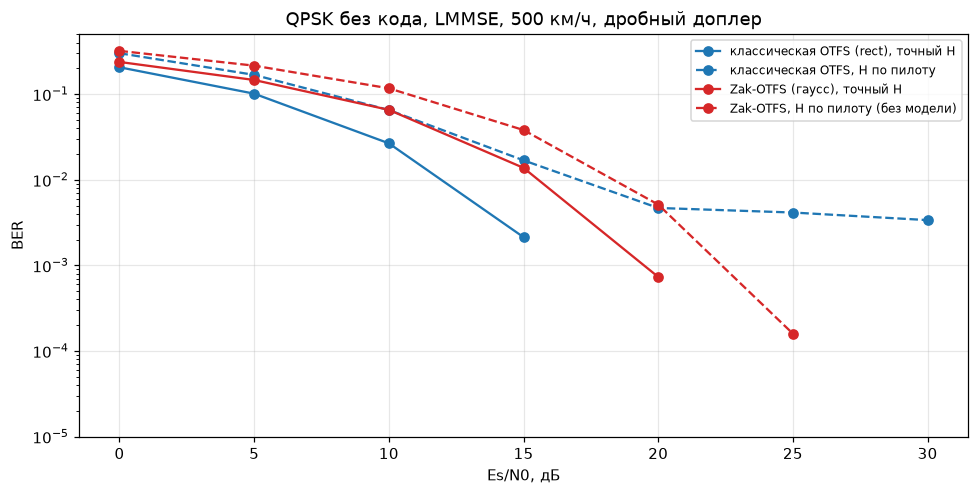

Защита: 23% кадра, пилот +23.8 дБ; оценка — все отсчёты окна чтения, без порога и без модели лучей
rect : BER при 20 / 30 дБ: точный H 0.0e+00 / 0.0e+00, оценка 4.7e-03 / 3.4e-03
gauss: BER при 20 / 30 дБ: точный H 7.3e-04 / 0.0e+00, оценка 5.1e-03 / 0.0e+00


In [7]:
GUARD = np.zeros((M, N), bool)
GUARD[kp - (P_PATHS - 1) - 3:kp + P_PATHS + 3] = True         # окно чтения пилота + задержки данных, которые в него затекают; все доплеры
DATA = ~GUARD.ravel(); XP = np.sqrt(GUARD.sum())
setups = ("rect", "gauss")
W = {k: noise_whitener(k) for k in setups}; Winv = {k: np.linalg.inv(W[k]) for k in setups}
snrs = np.arange(0, 31, 5)
ber = {f"{k}_{m}": np.zeros(len(snrs)) for k in setups for m in ("true", "est")}
for f in range(FRAMES):
    pth = draw_paths(rng)
    for kind in setups:
        H = W[kind] @ eff_matrix(pth, kind)
        b, xd = qpsk_bits(1, MN, rng); x = xd[0] * DATA; x[kp * N + lp] = XP
        for i, snr in enumerate(snrs):
            n0 = 10 ** (-snr / 10)
            yw = H @ x + np.sqrt(n0) * crandn(MN, rng)          # после выбеливания шум белый
            d, q, h = read_h((Winv[kind] @ yw).reshape(M, N), kp, lp, (-3, P_PATHS + 2), N // 2 - 1)
            h = h / XP
            Hest = W[kind] @ predict_H(d, q, h)
            for Hd, tag in ((H, "true"), (Hest, "est")):
                z = lmmse(Hd[:, DATA], (yw - Hd[:, kp * N + lp] * XP)[None], n0)[0]
                ber[f"{kind}_{tag}"][i] += np.mean(hard_bits(z) != b[0, DATA])
ber = {k: v / FRAMES for k, v in ber.items()}
fig, a = plt.subplots(figsize=(9, 4.6))
for k, c, ls, lab in (("rect_true", "C0", "-", "классическая OTFS (rect), точный H"), ("rect_est", "C0", "--", "классическая OTFS, H по пилоту"),
                      ("gauss_true", "C3", "-", "Zak-OTFS (гаусс), точный H"), ("gauss_est", "C3", "--", "Zak-OTFS, H по пилоту (без модели)")):
    ok = ber[k] > 0
    a.semilogy(snrs[ok], ber[k][ok], c + "o", ls=ls, label=lab)
a.set_ylim(1e-5, 0.5); a.set_xlabel("Es/N0, дБ"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"QPSK без кода, LMMSE, {SPEED_KMH} км/ч, дробный доплер")
plt.tight_layout(); plt.show()
print(f"Защита: {GUARD.mean():.0%} кадра, пилот +{10*np.log10(XP**2):.1f} дБ; оценка — все отсчёты окна чтения, без порога и без модели лучей")
for kind in setups:
    print(f"{kind:5}: BER при 20 / 30 дБ: точный H {ber[kind+'_true'][4]:.1e} / {ber[kind+'_true'][6]:.1e}, оценка {ber[kind+'_est'][4]:.1e} / {ber[kind+'_est'][6]:.1e}")

## 6. Сенсинг: доплер цели по одному пилоту
Тот же пилот — это радарный импульс: его отклик в DD и есть «радарная картинка» $h_\text{eff}(\tau,\nu)$. Оценим дробный доплер одиночной цели по трём отсчётам вокруг пика:
- у **гаусса** $\log|Y|$ — парабола, и интерполяция по трём точкам **точна**;
- у **прямоугольника** пик — ядро Дирихле, а парабола по $|Y|$ даёт систематическое смещение, которое не уходит с ростом SNR.

При 30 дБ: rect ~150 Гц (16 % бина) — пол смещения, гаусс ~20 Гц и продолжает падать. Это довод Zak-OTFS для ISAC (совмещённой связи и радиолокации): одна и та же форма волны и передаёт данные, и меряет задержку и доплер с точностью лучше бина.

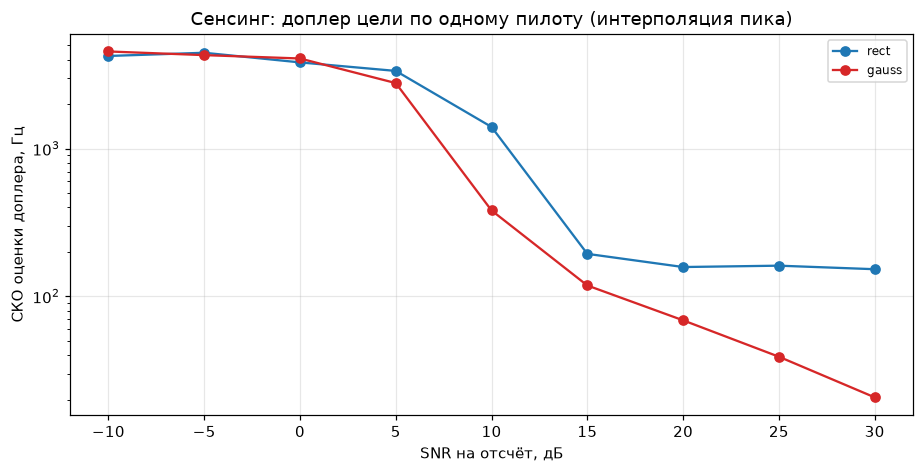

СКО доплера при 30 дБ: rect 152.7 Гц (смещение интерполяции Дирихле), гаусс 20.71 Гц; бин 1/T = 938 Гц


In [8]:
def nu_estimate(Y, kind):
    """дробный доплер по трём отсчётам вокруг пика: парабола по log|Y| (точна для гаусса) или по |Y| (для rect)"""
    row = Y[kp]; i = np.argmax(np.abs(row))
    v = np.abs(row[[(i - 1) % N, i, (i + 1) % N]])
    v = np.log(v + 1e-30) if kind == "gauss" else v
    return i - lp + 0.5 * (v[0] - v[2]) / (v[0] - 2 * v[1] + v[2])
snrs6 = np.arange(-10, 31, 5); trials = 200
rm = {k: [] for k in ("rect", "gauss")}
for kind in rm:
    gt, gr = windows(kind)
    base = tx(Pp, gt)
    for snr in snrs6:
        err = []
        for t in range(trials):
            nu = rng.uniform(-K_MAX, K_MAX)
            r = channel(base, [(1.0, 0, nu / T)]) + np.sqrt(10 ** (-snr / 10)) * crandn(len(NABS), rng)
            err.append(nu_estimate(rx(r, gr), kind) - nu)
        rm[kind].append(np.sqrt(np.mean(np.square(err))))
fig, a = plt.subplots(figsize=(8.5, 4.4))
for kind, c in (("rect", "C0"), ("gauss", "C3")):
    a.semilogy(snrs6, np.array(rm[kind]) / T, c + "o-", label=kind)
a.set_xlabel("SNR на отсчёт, дБ"); a.set_ylabel("СКО оценки доплера, Гц"); a.legend(fontsize=8)
a.set_title("Сенсинг: доплер цели по одному пилоту (интерполяция пика)")
plt.tight_layout(); plt.show()
print(f"СКО доплера при 30 дБ: rect {rm['rect'][-1]/T:.1f} Гц (смещение интерполяции Дирихле), гаусс {rm['gauss'][-1]/T:.2f} Гц; бин 1/T = {1/T:.0f} Гц")

## Сравнение: OFDM, OTFS 1.0, Zak-OTFS
| | OFDM | OTFS 1.0 (`otfs_sim`) | Zak-OTFS |
|---|---|---|---|
| Построение | IFFT по поднесущим | ISFFT + OFDM-модулятор | обратное преобразование Зака + фильтр в DD |
| Импульс | прямоугольник на символ | прямоугольник на кадр | любой: sinc, гаусс, RRC, гаусс-sinc |
| Канал в своей области | $H[m,n]$ меняется везде | 2D-свёртка с фазами, зависящими от модема | скрученная свёртка, фаза — свойство плоскости DD |
| Дробный доплер | ICI | хвосты Дирихле, пол оценки | локализованный отклик, предсказуемо |
| Оценка канала | пилоты + интерполяция | поиск лучей (модель) | чтение отклика на пилот (без модели) |
| Ортогональность символов | да | да | у гаусса нет (−3…5 дБ при точном H) |
| Сенсинг | отдельные опорные | грубый (смещение Дирихле) | точный, точнее бина |
| Условие работы | $\nu_{\max} T\ll1$ | $\nu_{\max}<\nu_p/2$ | кристаллизация: $\tau_{\max}<\tau_p$, $2\nu_{\max}+\text{фильтр}<\nu_p$ |

Дальше в серии — **AFDM** и **OCDM**: тоже разделяют задержку и доплер, но в одномерном кадре на чирпах, без двумерной решётки.

## Что покрутить
- `SIGMA = 0.15` или `0.4` — в разделе 4 предсказание ухудшается с обеих сторон оптимума, в разделе 5 меняется цена неортогональности
- `SPEED_KMH = 2000` — $\nu_{\max}\approx7.9$ бина, почти $\nu_p/2$: кристаллизация нарушена, Zak-OTFS теряет предсказуемость, как на правом графике раздела 4
- `DF = 30e3` (вдвое шире $\nu_p$) при той же скорости — кристаллизация возвращается, но $\tau_p$ вдвое короче: для длинных задержек это уже риск
- `P_PATHS = 2` — меньше разнесения, разрыв rect/гаусс при точном H меняется
- в разделе 6 поставить `nu = 3.5` (ровно полбина) для всех испытаний — смещение rect максимально